In [5]:
import numpy as np
from scipy.integrate import solve_ivp
from tools import Config
import matplotlib.pyplot as plt
from scipy.optimize import root
from tools_eco import followpars, followpars_with_eqnature, simulation_with_pulse
from tools_eco import foodweb_switching_special, foodweb_jacobian_switching_special

In [41]:
pars_test = Config(dict(muC=2e-2, muH=3e-4, e=0.2, aH=1e-4, Th=7, 
                        aU=1e-3, rH=4e-3, K=3000, nu=7e-2, b = 0, w = 0.8))
y0 = [500, 1000, 2000]

In [44]:
Tmax = 10000
tspan = np.linspace(0, Tmax, Tmax * 2)
rhs = lambda t, y: foodweb_switching_special(y, pars_test)
y0 = [500, 1000, 1000]
sol = solve_ivp(rhs, [0, Tmax], y0, t_eval=tspan)


(0.0, 100.0)

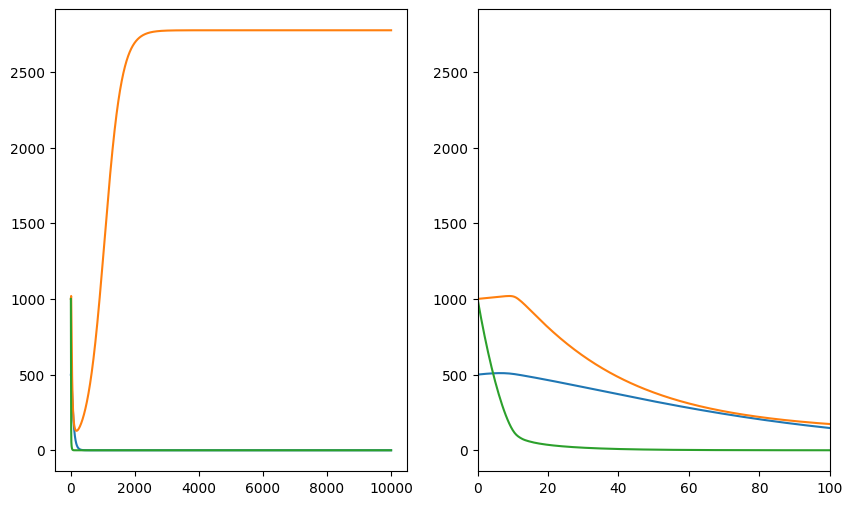

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].plot(sol.t, sol.y[0], label = 'Consumer')
axes[0].plot(sol.t, sol.y[1], label = 'Herbiovore') 
axes[0].plot(sol.t, sol.y[2], label = 'Carcasses')

Tend = 100
axes[1].plot(sol.t, sol.y[0], label = 'Consumer')
axes[1].plot(sol.t, sol.y[1], label = 'Herbiovore') 
axes[1].plot(sol.t, sol.y[2], label = 'Carcasses')
axes[1].set_xlim(0, Tend)

In [36]:
y0 = [500, 800, 1000]
pulse_freq = 30
pulse_amp = 2000
Tmax = 90
sol_pulse = simulation_with_pulse(foodweb_switching_special, pulse_freq, pulse_amp, Tmax, 
                                  y0, pars_test, None, None)
tspan = np.linspace(Tmax, Tmax + 280)
sol = solve_ivp(rhs, t_span = [Tmax, Tmax + 280], y0 = sol_pulse.y[-1, :], t_eval=tspan)


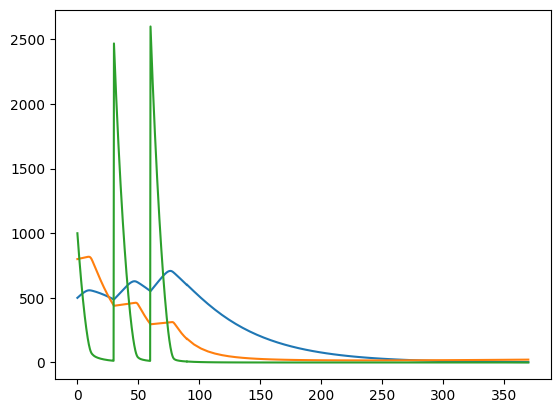

In [37]:
plt.plot(sol_pulse.t, sol_pulse.y[:,0], label = 'Consumer')
plt.plot(sol_pulse.t, sol_pulse.y[:,1], label = 'Herbiovore')
plt.plot(sol_pulse.t, sol_pulse.y[:,2], label = 'Carcasses')
plt.plot(sol.t, sol.y[0], label = 'Consumer', color = "C0")
plt.plot(sol.t, sol.y[1], label = 'Herbiovore', color = "C1")
plt.plot(sol.t, sol.y[2], label = 'Carcasses', color = "C2")